In [ ]:
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Flatten
from keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np
import random

In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [4]:
x_train = x_train / 255
x_test = x_test / 255

In [ ]:
# Display digits 0 to 9 before training

plt.figure(figsize=(10, 4))

for i in range(10):
    n = np.where(y_test == i)[0][0]

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[n], cmap='gray')
    plt.title("Digit: " + str(i))
    plt.axis('off')

plt.suptitle("MNIST Digits Before Training")
plt.show()

In [5]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

c:\Users\Dnyanehswari\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [6]:
model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [7]:
H = model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=5
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7382 - loss: 1.0428 - val_accuracy: 0.9020 - val_loss: 0.3586
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9023 - loss: 0.3524 - val_accuracy: 0.9192 - val_loss: 0.2909
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9156 - loss: 0.2962 - val_accuracy: 0.9277 - val_loss: 0.2600
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9250 - loss: 0.2637 - val_accuracy: 0.9327 - val_loss: 0.2360
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9353 - loss: 0.2343 - val_accuracy: 0.9381 - val_loss: 0.2187


In [8]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Loss = %.3f" % test_loss)
print("Accuracy = %.3f" % test_acc)


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9273 - loss: 0.2526
Loss = 0.219
Accuracy = 0.938


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


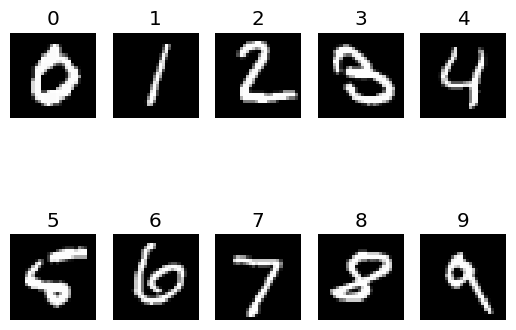

In [23]:

prediction = model.predict(x_test)


for i in range(10):
    n = np.where(y_test == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[n], cmap='gray')
    plt.title(str(i))
    plt.axis('off')

plt.show()


In [24]:
for i in range(10):
    n = np.where(y_test == i)[0][0]
    print("Digit:", i, "Prediction:", np.argmax(prediction[n]))

Digit: 0 Prediction: 0
Digit: 1 Prediction: 1
Digit: 2 Prediction: 2
Digit: 3 Prediction: 3
Digit: 4 Prediction: 4
Digit: 5 Prediction: 6
Digit: 6 Prediction: 6
Digit: 7 Prediction: 7
Digit: 8 Prediction: 8
Digit: 9 Prediction: 9


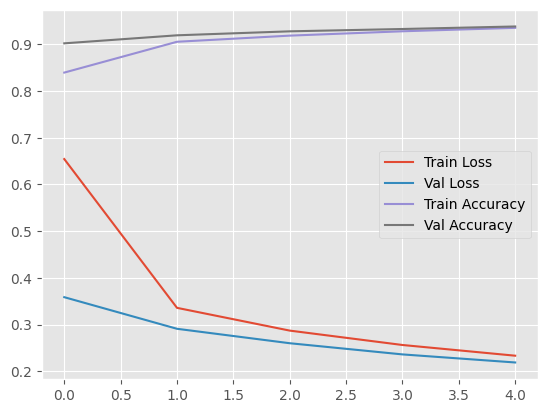

In [26]:

plt.plot(H.history["loss"], label="Train Loss")
plt.plot(H.history["val_loss"], label="Val Loss")
plt.plot(H.history["accuracy"], label="Train Accuracy")
plt.plot(H.history["val_accuracy"], label="Val Accuracy")

plt.legend()
plt.show()
